# Lab 28-04 · Checking the Answers Behind the Question Banks

Companion to [chapter 28-04](../../chapters/28-04-question-banks-digital-ai-memory-interconnect.md). Every part asks you to **predict first**, then run. All device parameters and likelihood ratios are the chapter's assumptions.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import qbank as qb

## Part 1 · An iso-power claim

Example 28-04.1: performance +25% at the same power, capacitance +10%.

**Predict:** the energy-per-operation reduction needed if IPC rises 20% instead of 15%.

IPC x1.15: f x1.087, power factor 1.413, required reduction 29.2%
IPC x1.2: f x1.042, power factor 1.243, required reduction 19.6%


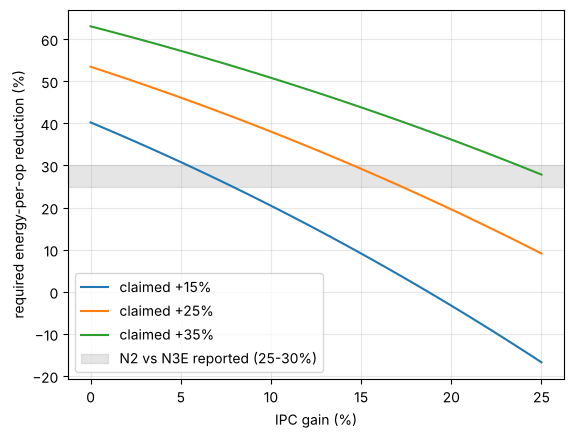

In [2]:
for g in (1.15, 1.20):
    f, p, r = qb.iso_power(1.25, g, 1.10)
    print(f"IPC x{g}: f x{f:.3f}, power factor {p:.3f}, required reduction {100*r:.1f}%")
g = np.linspace(1.0, 1.25, 101)
for R in (1.15, 1.25, 1.35):
    plt.plot(100*(g - 1), [100*qb.iso_power(R, x, 1.10)[2] for x in g], label=f'claimed +{round(100*(R-1))}%')
plt.axhspan(25, 30, color='grey', alpha=0.2, label='N2 vs N3E reported (25-30%)')
plt.xlabel('IPC gain (%)'); plt.ylabel('required energy-per-op reduction (%)')
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 2 · Decode against batch

Example 28-04.2: 2 PFLOP/s dense FP8, 8 TB/s.

**Predict:** the batch at the ridge with 4-bit weights, and the share of peak at batch 16.

ridge = 250 FLOP/byte
8-bit: batch at ridge 125.0, share at batch 16 12.8%
4-bit: batch at ridge 62.5, share at batch 16 25.6%


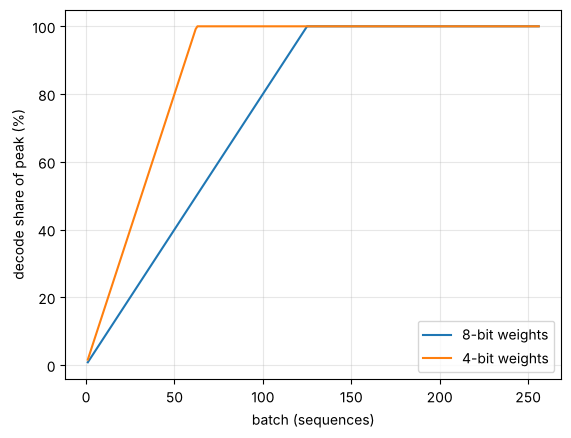

In [3]:
F, BW = 2e15, 8e12
print(f"ridge = {qb.ridge_point(F, BW):.0f} FLOP/byte")
for bw_bytes, name in ((1, '8-bit'), (0.5, '4-bit')):
    b16 = qb.attainable(qb.decode_intensity(16, bw_bytes), F, BW) / F
    print(f"{name}: batch at ridge {qb.batch_at_ridge(F, BW, bw_bytes):.1f}, share at batch 16 {100*b16:.1f}%")
batch = np.arange(1, 257)
for bw_bytes, name in ((1, '8-bit weights'), (0.5, '4-bit weights')):
    plt.plot(batch, [100*qb.attainable(qb.decode_intensity(b, bw_bytes), F, BW)/F for b in batch], label=name)
plt.xlabel('batch (sequences)'); plt.ylabel('decode share of peak (%)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 3 · Memory power at rising pin rates

**Predict:** one 2,048-bit stack at 11.7 Gb/s and 6.5 pJ/bit at full read bandwidth, and eight stacks.

stack bandwidth 2995.2 GB/s
5.5 pJ/bit: 132 W per stack
6.5 pJ/bit: 156 W per stack
7.5 pJ/bit: 180 W per stack
eight stacks at 6.5 pJ/bit: 1246 W


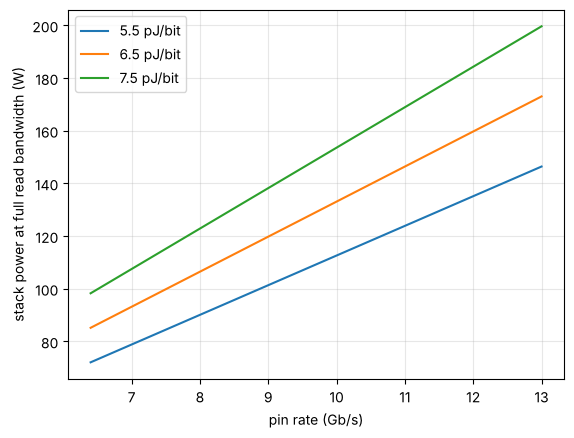

In [4]:
s = qb.stack_gbs(2048, 11.7)
print(f"stack bandwidth {s:.1f} GB/s")
for e in (5.5, 6.5, 7.5):
    print(f"{e} pJ/bit: {qb.link_power_w(s*1e9, e):.0f} W per stack")
print(f"eight stacks at 6.5 pJ/bit: {8*qb.link_power_w(s*1e9, 6.5):.0f} W")
rate = np.linspace(6.4, 13, 100)
for e in (5.5, 6.5, 7.5):
    plt.plot(rate, [qb.link_power_w(qb.stack_gbs(2048, r)*1e9, e) for r in rate], label=f'{e} pJ/bit')
plt.xlabel('pin rate (Gb/s)'); plt.ylabel('stack power at full read bandwidth (W)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 4 · Scoring an interview

Example 28-04.6: prior 0.5; ratios 3, 3, 0.4, 1, 3.

**Predict:** the posterior after a sixth, evasive answer (ratio 0.4).

odds 4.32, probability 81.2%


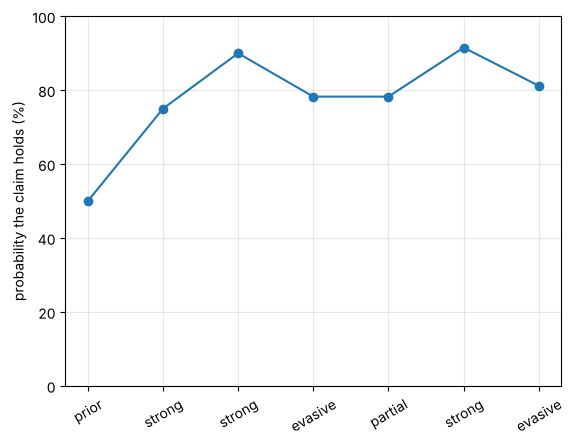

In [5]:
ratios = [3, 3, 0.4, 1, 3, 0.4]
odds, p = qb.posterior(0.5, ratios)
print(f"odds {odds:.2f}, probability {100*p:.1f}%")
traj = qb.trajectory(0.5, ratios)
plt.plot(range(len(traj)), [100*x for x in traj], 'o-')
plt.xticks(range(len(traj)), ['prior', 'strong', 'strong', 'evasive', 'partial', 'strong', 'evasive'], rotation=30)
plt.ylabel('probability the claim holds (%)'); plt.ylim(0, 100); plt.grid(True, alpha=0.3); plt.show()